# Lab 05: How to manage what an agent sees

**Notebook 1 of 2: meet context and skills on a house-sitter's notes**

## Goal

We are away for the weekend. A friend is looking after the flat and the cat, and a model answers her questions
from the notes we left. We build that helper three ways: with no notes, with every note in the system prompt, and
with a short list and one tool that opens a note when the model asks for it. Then we turn a note into an **Agent
Skill**, the folder format that coding agents and other agent programs read. The moment to watch for: given only
a list of names with one line each, the model asks for the one note the question needs. Give the same notes names
that say nothing, and it opens notes it does not need.

Nothing here touches the music shop yet. This notebook is the playground; notebook 2 takes the same idea to the
Chinook support desk.

## What you will learn

- How to read from `usage.prompt_tokens` how much text one call sent to the model, and why a long system prompt is
  paid for again on every call.
- How to give a model a list of notes and one tool, `open_note`, and write the small loop that opens what it asks
  for.
- Why the names and the one-line descriptions in that list decide which notes get opened.
- How an Agent Skill is laid out: a folder with a `SKILL.md` that has a `name` and a `description` at the top, the
  instructions below them, and reference files beside it.
- How to load a skill in three levels: the list in every call, the instructions on request, a reference file only
  when the instructions point to it.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import json
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


One more cell of setup: the client. We call the model with `client.chat.completions.create`, the Chat Completions
API. It is the plainest form of a model call: we send a list of messages and get one message back, which is why we
use it to see what a request holds.

Two settings, one line each. `timeout=60` makes a request that gets stuck fail after a minute. Every call below
passes `reasoning_effort=EFFORT or omit`: it sends the effort set in `models.env`, and `omit` leaves the argument
out when that setting is empty.

In [2]:
from openai import OpenAI, omit

client = OpenAI(timeout=60, max_retries=2)

---

## Part A: Ask a question the model cannot answer alone

Our friend Lina is in the flat. We are on a plane. She types a question to the helper we left her:

> How much do I feed Mishmish?

Mishmish is our cat. How much she eats is written in our notes, and nowhere else. A model writes its reply from
two things: its training data and the text in the request. Our notes are in neither, so we can watch the model
fail first, and then see what fixes it.

`BASE` is the system prompt: who the model is answering for, and how long the answer should be.

In [3]:
BASE = (
    "You answer a house-sitter's questions for the owner of the flat, who is away for the weekend. "
    "Answer in one or two sentences."
)
QUESTION = "How much do I feed Mishmish?"

response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {"role": "system", "content": BASE},
        {"role": "user", "content": QUESTION},
    ],
    reasoning_effort=EFFORT or omit,
)

print(response.choices[0].message.content)
print("input tokens:", response.usage.prompt_tokens)

I don’t know how much Mishmish should be fed—please check the feeding instructions or ask the owner.
input tokens: 48


In our run the model said it does not know how much Mishmish should be fed, and sent Lina back to the feeding instructions or to the owner.

**Notice:** it did not make an amount up. Nothing in the request says what Mishmish eats, and the reply says so.

The second line is the number this lab is about. `response.usage.prompt_tokens` counts the **input tokens** of the
call: everything we sent, cut into tokens (pieces of words, about four characters each in English). Here that is
the system prompt, the question and a few tokens of formatting around them: 48 in all.

**Important:** the model keeps nothing between calls. Whatever it needs for an answer has to be inside the request,
every time. Everything a request holds is called the **context**, and choosing what goes into it is the subject of
this lab.

**Checkpoint A.** The reply says it does not have the feeding instructions, and the call sent about 48
input tokens.

---

## Part B: Put every note in the system prompt, and count what each question costs

The model needs our notes, so the first idea is the obvious one: send them all.

### The notes

Our notes are nine small files in the folder `house_notes/`, one per subject. We list them, then print the one about
the cat.

In [4]:
LAB = ROOT / "05_Context_And_Skills"
NOTES_DIR = LAB / "house_notes"

for path in sorted(NOTES_DIR.glob("*.md")):
    print(f"{path.name:15} {len(path.read_text()):4} characters")

alarm.md         401 characters
cat.md           528 characters
heating.md       492 characters
kitchen.md       468 characters
laundry.md       357 characters
neighbours.md    410 characters
plants.md        337 characters
post.md          329 characters
wifi.md          284 characters


In [5]:
print((NOTES_DIR / "cat.md").read_text())

# Mishmish, the cat

- **Food:** half a cup of dry food at 7 in the morning and half a cup at 6 in the evening. The bag is in the
  cupboard under the sink, with the measuring cup inside it.
- **Treats:** two a day at most, from the jar on top of the fridge. She will ask for more.
- **Water:** fresh water every morning in the blue bowl. She does not drink from the steel one.
- **Doors:** she is an indoor cat. Keep the balcony door closed.
- **Litter tray:** scoop it every evening. The bags are on the shelf above the tray.



Nine notes, each a few hundred characters. The cat's note has the answer to Lina's question in its first line:
half a cup of dry food at 7 in the morning and half a cup at 6 in the evening.

### Every note in the system prompt

We join the nine notes into one text and put it in the system prompt, after `BASE` and one rule: answer only from
the notes. `"\n\n".join(...)` puts a blank line between one note and the next.

In [6]:
all_notes = "\n\n".join(path.read_text().strip() for path in sorted(NOTES_DIR.glob("*.md")))

MANUAL = (
    BASE
    + " Answer only from the owner's notes below. If the notes do not cover a question, say so.\n\n"
    + all_notes
)

print(len(MANUAL), "characters")

3828 characters


The same call as in Part A, with `MANUAL` as the system prompt. We write it as a small function, `ask_with_manual`,
because we are about to ask two questions the same way.

In [7]:
def ask_with_manual(question):
    # One call: the whole manual in the system prompt, then the question
    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {"role": "system", "content": MANUAL},
            {"role": "user", "content": question},
        ],
        reasoning_effort=EFFORT or omit,
    )
    print(response.choices[0].message.content)
    print("input tokens:", response.usage.prompt_tokens)


ask_with_manual(QUESTION)

Give Mishmish half a cup of dry food at 7 in the morning and half a cup at 6 in the evening.
input tokens: 1011


Half a cup of dry food at 7 in the morning and half a cup at 6 in the evening: the first line of the cat's note. The model answered from our notes.

Now look at the count: 1,011 input tokens, against 48 in Part A. The answer needed one line of
one note. The call sent all nine.

A second question, about something else:

In [8]:
ask_with_manual("What is the wifi password?")

The Wi-Fi password is `apricot-2019`.
input tokens: 1008


Right again, and 1,008 input tokens: almost the same count. The two questions needed different notes, and
both calls carried every note.

That is the cost of the **fat prompt**, a system prompt that holds everything:

- **Every call pays for all of it,** whatever the question. Ten questions over the weekend send the nine notes ten
  times.
- **It grows with the notes, not with the question.** Nine short notes are about a thousand tokens. A real house
  manual, or a company's rule book, can be fifty times that, on every call.
- **The model has to find one line among all of them.** With nine notes that is easy. The more unrelated text a
  request carries, the more often a model picks up the wrong line.

**Checkpoint B.** Both questions are answered from the notes (half a cup twice a day; `apricot-2019`), and each call
sends about 1,011 input tokens.

---

## Part C: Keep a list on the fridge and let the model open one note

A person would not read the whole manual to feed the cat. They would look at a list on the fridge, see which note
is about the cat, and open that one. We give the model the same two things: the list, and a way to open a note.

### The list

One line per note: its name, and when to use it. This list is all the model will be sent about the notes in
advance.

In [9]:
FRIDGE = {
    "wifi": "use when someone needs the wifi or the TV",
    "alarm": "use when leaving or coming back to the flat, or when the alarm goes off",
    "heating": "use when the flat is cold or there is no hot water",
    "kitchen": "use for the coffee machine, the oven or the dishwasher",
    "laundry": "use when washing or drying clothes",
    "cat": "use when feeding the cat or when she seems ill",
    "plants": "use when watering the plants",
    "post": "use for letters, parcels and couriers",
    "neighbours": "use when a neighbour or the building manager is needed",
}

fridge_list = "\n".join(f"- {name}: {when}" for name, when in FRIDGE.items())
print(fridge_list)

- wifi: use when someone needs the wifi or the TV
- alarm: use when leaving or coming back to the flat, or when the alarm goes off
- heating: use when the flat is cold or there is no hot water
- kitchen: use for the coffee machine, the oven or the dishwasher
- laundry: use when washing or drying clothes
- cat: use when feeding the cat or when she seems ill
- plants: use when watering the plants
- post: use for letters, parcels and couriers
- neighbours: use when a neighbour or the building manager is needed


### A function that opens one note

`open_note` is ordinary Python: it takes a name from the list and returns that file's text. We call it ourselves
first.

In [10]:
def open_note(name):
    # Return the text of one note
    return (NOTES_DIR / f"{name}.md").read_text()


print(open_note("plants"))

# Plants

- **Balcony tomatoes:** one full watering can every evening, after sunset.
- **The fig tree in the living room:** one glass of water on Saturday. No more, even if it looks sad.
- **The orchid in the bathroom:** do not water it. It was watered before we left.
- The watering can is under the kitchen sink, next to the cat food.



### Describe the function to the model

The model cannot run `open_note`. It can only **ask** for it, and for that it needs a description of the function,
called a **tool schema**. We send it in `tools=[...]`:

- `name`: what the model writes to ask for this tool.
- `description`: what the tool does.
- `parameters`: the arguments. Here one string, `name`, and `enum` lists the only values it may take: the nine
  names on the fridge list. The model cannot ask for a note that does not exist.
- `strict: True`: the arguments must match this schema exactly.

In [11]:
open_note_tool = {
    "type": "function",
    "function": {
        "name": "open_note",
        "description": "Open one of the owner's notes and read it.",
        "parameters": {
            "type": "object",
            "properties": {"name": {"type": "string", "enum": list(FRIDGE)}},
            "required": ["name"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

The new system prompt is the **thin prompt**: `BASE`, how to use the list, and the list. No note is in it.

In [12]:
THIN = (
    BASE
    + " Answer only from the owner's notes. The list on the fridge says which notes exist. "
    + "Open a note with open_note when you need it. If no note covers a question, say so.\n\n"
    + "Notes:\n"
    + fridge_list
)

print(THIN)

You answer a house-sitter's questions for the owner of the flat, who is away for the weekend. Answer in one or two sentences. Answer only from the owner's notes. The list on the fridge says which notes exist. Open a note with open_note when you need it. If no note covers a question, say so.

Notes:
- wifi: use when someone needs the wifi or the TV
- alarm: use when leaving or coming back to the flat, or when the alarm goes off
- heating: use when the flat is cold or there is no hot water
- kitchen: use for the coffee machine, the oven or the dishwasher
- laundry: use when washing or drying clothes
- cat: use when feeding the cat or when she seems ill
- plants: use when watering the plants
- post: use for letters, parcels and couriers
- neighbours: use when a neighbour or the building manager is needed


### The model asks for a note

Lina's question again, with the thin prompt and the tool. This time we print three things: the input tokens, the
text of the reply, and `tool_calls`, the list of tools the model asked for.

In [13]:
messages = [
    {"role": "system", "content": THIN},
    {"role": "user", "content": QUESTION},
]

response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=[open_note_tool], reasoning_effort=EFFORT or omit
)
reply = response.choices[0].message

print("input tokens:", response.usage.prompt_tokens)
print("text:", reply.content)
for call in reply.tool_calls:
    print("asked for:", call.function.name, call.function.arguments)

input tokens: 370
text: None
asked for: open_note {"name":"cat"}


Read the three lines:

- **input tokens:** 370, against 1,011 with the whole manual. The list and the tool schema cost
  far less than the nine notes.
- **text:** `None`. The model wrote no answer.
- **asked for:** `open_note` with `{"name":"cat"}`. From nine names and nine short lines, it picked the cat's note.

**Notice** what has not happened: no note was opened. The model wrote a request, and the request is text. Opening
the note is our code's job.

### Our code opens the note and sends it back

Three steps:

1. `messages.append(reply)` adds the model's request to the conversation, so the next call shows what was asked.
2. `json.loads` turns the arguments, a string of JSON, into a dictionary, and `open_note(**arguments)` runs the
   function with it. `**arguments` passes each key as a named argument, so this is `open_note(name="cat")`.
3. The note goes back as a message with the role `tool`. Its `tool_call_id` repeats the request's id, so the model
   can match the note to its request.

Then we call the model again with the longer list of messages.

In [14]:
call = reply.tool_calls[0]
arguments = json.loads(call.function.arguments)
note = open_note(**arguments)

messages.append(reply)
messages.append({"role": "tool", "tool_call_id": call.id, "content": note})

response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=[open_note_tool], reasoning_effort=EFFORT or omit
)

print("input tokens:", response.usage.prompt_tokens)
print(response.choices[0].message.content)

input tokens: 537
Give Mishmish half a cup of dry food at 7 a.m. and half a cup at 6 p.m. She can have up to two treats a day.


Now there is an answer: half a cup at 7 a.m. and half a cup at 6 p.m., and up to two treats a day. Both facts are in the cat's note.

The second call sent 537 input tokens: the 370 of the first call again, plus the model's
request and the cat's note. The other eight notes were never sent.

### The same steps in a loop

We did two calls by hand. A question may need none, one or several notes, so we put the steps in a loop: call the
model; if it asked for tools, run each one and send the results back; stop when a reply has no tool call in it.

`ask` takes the question, a system prompt, the tool schemas and `functions`, a dictionary from each tool's name to
the Python function that runs it. It prints the input tokens of every call and every request the model makes.
`max_turns` stops a model that keeps asking.

In [15]:
def ask(question, system, tools, functions, max_turns=8):
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]

    for turn in range(max_turns):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=tools, reasoning_effort=EFFORT or omit
        )
        reply = response.choices[0].message
        print(f"call {turn + 1}: {response.usage.prompt_tokens} input tokens")

        # No tool call in the reply: it is the answer
        if not reply.tool_calls:
            return reply.content

        # Otherwise run each tool the model asked for and add the result to the conversation
        messages.append(reply)
        for call in reply.tool_calls:
            arguments = json.loads(call.function.arguments)
            print("   the model asked for:", call.function.name, arguments)
            result = functions[call.function.name](**arguments)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

    return "Stopped: the model was still asking for tools after max_turns calls."

We try the loop on the wifi question. Before you run it: which note will the model ask for, and how many calls
will there be?

In [16]:
print(ask("What is the wifi password?", THIN, [open_note_tool], {"open_note": open_note}))

call 1: 367 input tokens
   the model asked for: open_note {'name': 'wifi'}


call 2: 475 input tokens
The Wi‑Fi password is **apricot-2019**.


Two calls. On the first, 367 input tokens, the model asked for `wifi`. On the second, 475, it answered with the password. It opened one note out of nine.

Compare the two ways on this question:

| | Fat prompt (Part B) | Thin prompt with `open_note` |
|---|---|---|
| Calls to the model | 1 | 2 |
| Input tokens per call | 1,008 | 367, then 475 |
| Notes sent | all nine | one |
| Input tokens for the question | 1,008 | 842 |

The thin way makes one more call, and each call is smaller. Even with the extra call it sent less in all (842
against 1,008), because the note it needed is small. With nine short notes the saving is modest. It grows
with every note we add: a tenth note adds one line to the list, where the fat prompt would carry the whole note on
every call.

**Checkpoint C.** With the thin prompt the first reply has no text and one request, `open_note` with `cat`. After
our code sends the note back, the answer is half a cup twice a day. The loop answers the wifi question after
opening `wifi` only.

---

## Part D: See what the model opens when the list says nothing

In Part C the model picked the right note every time. Why? All it was sent about each note is a name and one line.
If the choice comes from those words, then taking the words away should spoil the choice. We test that.

We relabel the notes the way a folder of files often looks: `note-1` to `note-9`, each described as "house notes,
part N". The notes themselves do not change. `NUMBERED` maps each label to the file it stands for.

In [17]:
NUMBERED = {f"note-{number}": name for number, name in enumerate(FRIDGE, start=1)}

numbered_list = "\n".join(f"- {label}: house notes, part {label[-1]}" for label in NUMBERED)
print(numbered_list)

- note-1: house notes, part 1
- note-2: house notes, part 2
- note-3: house notes, part 3
- note-4: house notes, part 4
- note-5: house notes, part 5
- note-6: house notes, part 6
- note-7: house notes, part 7
- note-8: house notes, part 8
- note-9: house notes, part 9


The thin prompt with this list in place of the first one, the same tool with the new labels in its `enum`, and
`open_numbered`, which opens the file behind a label.

In [18]:
THIN_NUMBERED = THIN.replace(fridge_list, numbered_list)

numbered_tool = json.loads(json.dumps(open_note_tool))  # a separate copy of the schema
numbered_tool["function"]["parameters"]["properties"]["name"]["enum"] = list(NUMBERED)


def open_numbered(name):
    # Open the note behind a label such as note-6
    return open_note(NUMBERED[name])

`json.loads(json.dumps(...))` writes the schema out as text and reads it back, which gives a second dictionary we
can change without touching `open_note_tool`.

Lina's question once more. The cat's note is now `note-6`, and nothing in the list says so. Before you run it: how
many notes will the model open?

In [19]:
print(ask(QUESTION, THIN_NUMBERED, [numbered_tool], {"open_note": open_numbered}))

call 1: 369 input tokens
   the model asked for: open_note {'name': 'note-1'}


call 2: 479 input tokens
   the model asked for: open_note {'name': 'note-2'}
   the model asked for: open_note {'name': 'note-3'}
   the model asked for: open_note {'name': 'note-4'}
   the model asked for: open_note {'name': 'note-5'}
   the model asked for: open_note {'name': 'note-6'}
   the model asked for: open_note {'name': 'note-7'}
   the model asked for: open_note {'name': 'note-8'}
   the model asked for: open_note {'name': 'note-9'}


call 3: 1551 input tokens
Give Mishmish half a cup of dry food at 7 a.m. and another half cup at 6 p.m. You can give her at most two treats a day.


Read the printout from the top:

- **call 1:** the model asked for `note-1`. It had nothing to choose by, so it started at the top of the list. `note-1` is the wifi note.
- **call 2:** having read about the router, it asked for all the others in one reply, `note-2` to `note-9`.
- **call 3:** 1,551 input tokens. The request now holds all nine notes and the nine requests for them, which is more than the 1,011 of the fat prompt this list was meant to replace.

The answer is the same as in Part C: half a cup at 7 a.m. and half a cup at 6 p.m. Nothing in the reply shows that eight notes were opened for nothing. (On some of our runs the model opened the notes one at a time and stopped at `note-6`: six notes and seven calls.)

**Key lesson:** the model chooses a note from its name and the line beside it, because that is all the request says
about the notes. A list entry is a small piece of writing with a job: say what the note holds and when to use it. A
name that says nothing costs tokens on every question, and the answer can still come out right, so nobody notices.

**Checkpoint D.** With the labels `note-1` to `note-9` the model opens notes the question does not need (in our run
all nine), and the answer is still half a cup twice a day.

---

## Part E: Turn a note into an Agent Skill folder

Our helper works, and it has two weak points:

- The list lives in a notebook cell and the notes live in files. Add a note and forget the list, and the model is
  never told the note exists.
- Only this notebook can use them. Another program would need its own copy of `FRIDGE`.

An **Agent Skill** fixes both by putting the list entry inside the note. A skill is a folder, in a format that is
published as an open standard ([agentskills.io](https://agentskills.io)), and many agent programs read it: coding
agents in a terminal, editors, chat applications. What we built in Part C is that format's idea, written by hand.

### One skill folder

Three of our notes are already written as skills, in `house_skills/`. We print what the folder holds. `rglob("*")`
walks every file and folder under it, and `relative_to` prints each path from `house_skills/` down.

In [20]:
SKILLS_DIR = LAB / "house_skills"

for path in sorted(SKILLS_DIR.rglob("*")):
    print(path.relative_to(SKILLS_DIR))

cat
cat/SKILL.md
cat/references
cat/references/when-she-is-ill.md
plants
plants/SKILL.md
wifi
wifi/SKILL.md


Three folders, `cat`, `plants` and `wifi`, each with a file called `SKILL.md`. The `cat` folder has one more file,
in a folder called `references`. We print the cat's `SKILL.md` as it is on disk.

In [21]:
skill_text = (SKILLS_DIR / "cat" / "SKILL.md").read_text()
print(skill_text)

---
name: cat
description: How to look after Mishmish the cat, with her food, treats, water, doors and litter tray. Use when feeding the cat, when the sitter asks what she may eat or do, or when she seems ill.
---

# Mishmish, the cat

- **Food:** half a cup of dry food at 7 in the morning and half a cup at 6 in the evening. The bag is in the
  cupboard under the sink, with the measuring cup inside it.
- **Treats:** two a day at most, from the jar on top of the fridge. She will ask for more.
- **Water:** fresh water every morning in the blue bowl. She does not drink from the steel one.
- **Doors:** she is an indoor cat. Keep the balcony door closed.
- **Litter tray:** scoop it every evening. The bags are on the shelf above the tray.

**If she seems ill** (she has not eaten for a whole day, or she hides and will not come out): read
`references/when-she-is-ill.md` before you answer. It has the vet's number and what to do first.



The file has two parts, separated by lines of three dashes:

| Part | What it holds | Where we have seen it |
|---|---|---|
| The **frontmatter**, between the `---` lines | `name` and `description`: what the skill is about and when to use it | the line on the fridge list |
| The **body**, below the second `---` | the instructions themselves | the note |

The last two lines of the body are new. They point to another file, `references/when-she-is-ill.md`, and say when
to read it. That file is in the folder and not in the body, because most questions about the cat do not need it.

### Read the frontmatter in Python

The frontmatter is written in YAML, a plain format of `key: value` lines. Two steps turn the file into something
our code can use:

1. `skill_text.split("---", 2)` cuts the text at the first two `---` and gives three pieces: what is before the
   first one (nothing), the frontmatter, and the body.
2. `yaml.safe_load` reads the frontmatter into a dictionary.

In [22]:
import yaml

before, frontmatter, body = skill_text.split("---", 2)
meta = yaml.safe_load(frontmatter)

print(type(meta).__name__)
print("name:       ", meta["name"])
print("description:", meta["description"])

dict
name:        cat
description: How to look after Mishmish the cat, with her food, treats, water, doors and litter tray. Use when feeding the cat, when the sitter asks what she may eat or do, or when she seems ill.


A dictionary with two keys. The format has a few rules for them, and each has a reason:

- `name` is lowercase letters, digits and hyphens, and it is the same as the folder's name. A program finds the
  skill by it.
- `description` says what the skill does **and when to use it**. This is the sentence the model reads when it
  decides whether to load the skill, which is what Part D was about.

### Level 1: the list, built from the folders

We read every `SKILL.md` under `house_skills/` the same way and keep, for each skill, its frontmatter, its body and
its folder. Then the list is one line per skill, made from the frontmatter.

In [23]:
SKILLS = {}
for path in sorted(SKILLS_DIR.glob("*/SKILL.md")):
    before, frontmatter, body = path.read_text().split("---", 2)
    meta = yaml.safe_load(frontmatter)
    SKILLS[meta["name"]] = {"description": meta["description"], "body": body.strip(), "folder": path.parent}

skill_list = "\n".join(f"- {name}: {skill['description']}" for name, skill in SKILLS.items())
print(skill_list)

- cat: How to look after Mishmish the cat, with her food, treats, water, doors and litter tray. Use when feeding the cat, when the sitter asks what she may eat or do, or when she seems ill.
- plants: Which plants to water, how much and when. Use when the sitter asks about watering or about a plant that looks unwell.
- wifi: The wifi network and password, the router and the TV remotes. Use when someone needs the wifi or cannot get the TV to work.


This is the fridge list again, and this time nobody typed it. It is built from the files, so it cannot fall out of
step with them: add a folder with a `SKILL.md`, and the next run lists it.

The format calls this **level 1**. A skill is loaded in three levels, each only when it is needed:

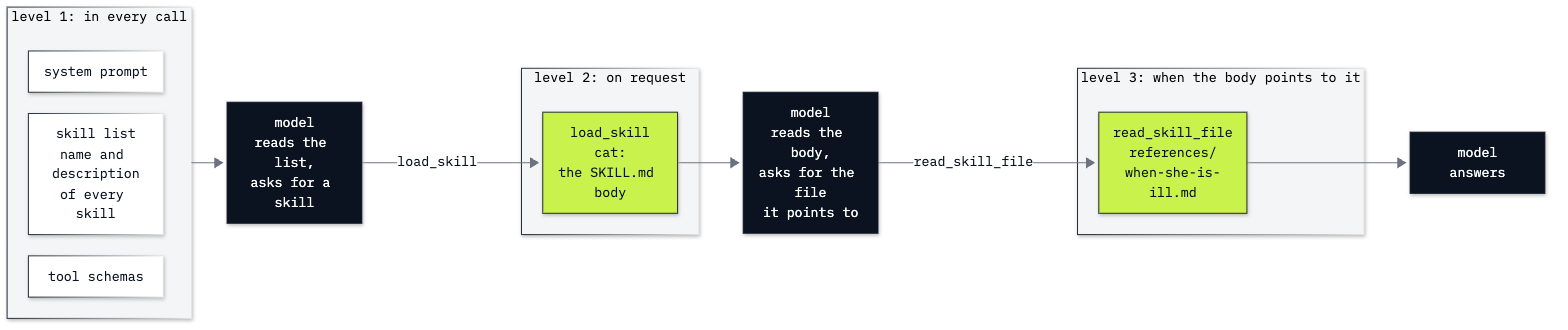

In [24]:
from IPython.display import Image

Image(str(LAB / "resources" / "house_skill_three_levels.png"), width=760)

How to read the picture, left to right:

- **Level 1, in every call:** the name and description of every skill. A few dozen tokens per skill.
- **Level 2, on request:** the body of one `SKILL.md`, sent when the model asks for that skill.
- **Level 3, when the body points to it:** a file inside the skill's folder, sent when the model asks for it by
  its path.

The dark boxes are the model's turns. The lime boxes are what our code sends back.

### Levels 2 and 3 as two functions

`load_skill(name)` returns a skill's body. `read_skill_file(skill, path)` returns one file inside a skill's folder.

⚠️ The `path` will come from the model, so `read_skill_file` must not read anything outside the skill's folder.
`resolve()` works out the full path, and the function refuses any file whose parent folders do not include the
skill's folder.

In [25]:
def load_skill(name):
    # Level 2: the body of one SKILL.md
    return SKILLS[name]["body"]


def read_skill_file(skill, path):
    # Level 3: one file inside the skill's folder, and nothing outside it
    folder = SKILLS[skill]["folder"].resolve()
    target = (folder / path).resolve()
    if folder not in target.parents or not target.is_file():
        return "No such file in this skill."
    return target.read_text()


print(read_skill_file("cat", "references/when-she-is-ill.md"))

# When Mishmish seems ill

1. **Check the easy things first.** Is there fresh water in the blue bowl? Did the food bag get wet? Is she shut in
   a room by mistake?
2. **Do not give her any medicine,** and no milk.
3. **Phone the vet:** Dr Haddad, 06-555-0142, open every day from 8 in the morning to 8 in the evening. Outside those
   hours the same number gives the night clinic.
4. **If the vet wants to see her:** the carrier is in the hall cupboard, top shelf. Put her blanket inside first and
   she walks in by herself.
5. **Then text me,** whatever the time.



The reference file: what to check first, the vet's number, where the carrier is. Useful on one bad day, and not
needed for a question about food.

### The model loads a skill

The next cell does three things, in this order:

1. **Two tool schemas,** `load_skill` and `read_skill_file`, in the same shape as `open_note_tool` in Part C. Two
   things differ: `enum` lists the three skill names instead of the nine notes, and `read_skill_file` takes two
   arguments, `skill` and `path`, both in `required`. `path` has no `enum`: it is free text written by the model,
   which is why the function checks it.
2. **The system prompt, `WITH_SKILLS`.** With the two schemas, this is level 1 as the model receives it: `BASE`,
   then the rule to answer only from the owner's skills (each skill holds the notes for one subject), then how to
   use the two tools (load a skill with `load_skill` when a question needs it, read a file inside it with
   `read_skill_file` when the skill says so), then what to do when no skill covers a question, and last the line
   `Skills:` and the three lines of `skill_list` printed above. No body and no reference file is in it.
3. **The run:** Lina's question with the `ask` loop from Part C. `skill_functions` maps each tool name to its
   Python function, as `{"open_note": open_note}` did.

In [26]:
skill_tools = [
    {
        "type": "function",
        "function": {
            "name": "load_skill",
            "description": "Load the full notes of one skill.",
            "parameters": {
                "type": "object",
                "properties": {"name": {"type": "string", "enum": list(SKILLS)}},
                "required": ["name"],
                "additionalProperties": False,
            },
            "strict": True,
        },
    },
    {
        "type": "function",
        "function": {
            "name": "read_skill_file",
            "description": "Read a file inside a skill's folder, when the skill's notes point to it.",
            "parameters": {
                "type": "object",
                "properties": {
                    "skill": {"type": "string", "enum": list(SKILLS)},
                    "path": {"type": "string", "description": "Path inside the skill folder"},
                },
                "required": ["skill", "path"],
                "additionalProperties": False,
            },
            "strict": True,
        },
    },
]

WITH_SKILLS = (
    BASE
    + " Answer only from the owner's skills. Each skill below holds the notes for one subject. "
    + "Load a skill with load_skill when a question needs it, and read a file inside it with read_skill_file "
    + "when the skill tells you to. If no skill covers a question, say so.\n\n"
    + "Skills:\n"
    + skill_list
)

skill_functions = {"load_skill": load_skill, "read_skill_file": read_skill_file}

print(ask(QUESTION, WITH_SKILLS, skill_tools, skill_functions))

call 1: 397 input tokens
   the model asked for: load_skill {'name': 'cat'}


call 2: 618 input tokens
Give Mishmish half a cup of dry food at 7 a.m. and another half cup at 6 p.m.


Two calls. On the first, 397 input tokens, the model read three descriptions and asked for `load_skill` with `cat`. Our code sent the body back as a tool result, and the second call, 618 input tokens, answered from it: half a cup at 7 a.m. and half a cup at 6 p.m.

The model did not ask for `read_skill_file`. The body's last lines say to read the reference when the cat seems ill, and this question is about food. The reference file stayed on disk and cost nothing.

**What this run does not show:** level 3 chosen by the model. We read the reference file ourselves, and the model
had no reason to ask for it. Challenge 1 gives it a reason, and in notebook 2 we watch it happen at the desk.

**Checkpoint E.** The frontmatter is a dictionary with `name` `cat` and a description; the list has three lines
built from the folders; for the feeding question the model asks for `load_skill` with `cat` and nothing else.

---

## What you can do now

- Read `usage.prompt_tokens` and say what a call sent, and why a fat system prompt is paid for on every call
  (Parts A and B).
- Give a model a list and one tool, run the tool it asks for, and put those steps in a loop (Part C).
- Write a list entry that tells the model when to open a note, and say what happens when it does not (Part D).
- Read an Agent Skill folder: the frontmatter, the body and a reference file (Part E).
- Build the skill list from the folders and load a skill level by level (Part E).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `Error code: 400 ... Function tools with reasoning_effort are not supported ...` | on this API the model calls tools only with the reasoning effort `none` | set `REASONING_EFFORT=none` in `models.env` and run the setup cell again |
| `yaml.scanner.ScannerError: mapping values are not allowed here` | a `description` in a `SKILL.md` contains a colon followed by a space, which YAML reads as a new key | reword the description, or put it in double quotes |
| `KeyError` in `load_skill` or `open_numbered` | the lists were changed after the tool schema was built, so the `enum` and the dictionary disagree | run the notebook again from the top |
| the model answers without opening a note | the model decides on every run | ask again; the rule "Answer only from the owner's notes" in the prompt is what sends it to the list |

## Challenge

1. **Give the model a reason to go to level 3.** Ask, with `WITH_SKILLS` and the `ask` loop: *Mishmish has not
   eaten since yesterday and she is hiding under the bed. What do I do?* Before you run it, write down which files
   you expect the model to read, and in which order. Expected: `load_skill` with `cat`, then `read_skill_file` with
   `references/when-she-is-ill.md`, then an answer with the vet's number.
2. **Write a skill of your own.** No note says when the bins go out. Create `my_house_skills/bins/SKILL.md` beside
   this notebook (a folder of your own, so that `house_skills/` stays as the lab ships it), with a `name`, a
   `description` that says when to use it, and a body of three or four lines (make the days up). Read it the way
   Part E read `house_skills/`, and add it with `SKILLS.update(...)`, as the solution does (it puts the reading loop
   in a function, `read_skills(folder)`). Then rebuild `skill_list` (the last two lines of the cell that built
   `SKILLS`), `skill_tools` and `WITH_SKILLS`, and ask *What day do the bins go out?* and then Lina's feeding
   question. Expected: the bins question loads `bins` and only `bins`; the
   feeding question still loads only `cat`.

The worked solution, run with its outputs, is in `solved/05a_meet_context_and_skills_solution.ipynb`.

## Going further

- **Use the same skills in a coding agent.** Because the format is shared, a skill folder works in other programs
  with no loader code from us. The folder `house_agent/` beside this notebook is set up for any coding agent:

  ```
  house_agent/
  ├── AGENTS.md              what the agent is for, and how to use the skills
  └── .agents/skills/
      ├── cat/               SKILL.md and references/when-she-is-ill.md
      ├── plants/            SKILL.md
      └── wifi/              SKILL.md
  ```

  The three skills are copies of the folders in `house_skills/`. `AGENTS.md` is the instruction file that coding
  agents look for in a project. Ours tells the agent that the notes are skills in `.agents/skills/`, to read only
  each skill's `name` and `description` first, to open a skill's `SKILL.md` only when the question is about its subject, and to open a reference file only when
  that `SKILL.md` says to: the three levels of Part E, written as instructions.

  Open your coding agent in `house_agent/` (Claude Code, Codex or another) and start the prompt with the line that
  sends it to that file:

  > Start by reading AGENTS.md. Then answer: how much do I feed Mishmish, and when?

  In our run with Codex, the agent read `AGENTS.md` and each skill's `name` and `description`, opened the whole of
  `.agents/skills/cat/SKILL.md` and no other skill's body, read no reference file, and answered half a cup at 7 in
  the morning and half a cup at 6 in the evening. Not every agent loads `AGENTS.md` on its own (Claude Code reads it only when there is no `CLAUDE.md` in the folder you open it in or in any folder above it), so the first line of the prompt makes sure it does.
  Some agents also find the skills by themselves: Codex and GitHub Copilot read skills from `.agents/skills/` (in Codex, type `/skills` to see them). Claude Code reads skills by itself only from `.claude/skills/`; here it reaches them
  through `AGENTS.md`.

  *Screenshot to add: a coding agent answering the feeding question from `house_agent/`, with the files it read.*

- **Check a skill against the format.** The Agent Skills project publishes a small validator,
  `skills-ref validate <folder>`, that checks the name, the description and the folder layout.
- **Make a big prompt cheaper without making it smaller.** `05_extra_prompt_caching.ipynb` in this folder measures
  what the API charges when the same long prompt is sent again.
- **Shorten a long conversation.** `05_extra_compaction.ipynb` replaces old messages with a summary and checks what
  that keeps and what it loses.

## Resources

- [Agent Skills: what skills are](https://agentskills.io/what-are-skills) and
  [the specification](https://agentskills.io/specification): the folder, the frontmatter fields and the three levels
- [Agent Skills: adding skills support to an agent](https://agentskills.io/client-implementation/adding-skills-support):
  the skill list and the loading tool, for people who write the agent
- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas and tool
  calls
- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `messages`, `tools`, `usage`
- [Claude Code: skills](https://code.claude.com/docs/en/skills),
  [Codex: skills](https://developers.openai.com/codex/skills) and
  [VS Code: agent skills](https://code.visualstudio.com/docs/copilot/customization/agent-skills): where each coding
  agent reads skill folders from
- [AGENTS.md](https://agents.md) and [Claude Code: AGENTS.md](https://code.claude.com/docs/en/memory#agents-md): the
  instruction file coding agents look for in a project, and when Claude Code reads it

Next: [notebook 2, context and skills at the Chinook desk](05b_context_and_skills_at_the_desk.ipynb).